In [2]:
import pandas as pd 
import seaborn as sns
from matplotlib import pyplot as plt 

df=pd.read_csv("churn.csv")
df.head()

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
0,8,0,38,0,4370,71,5,17,3,1,1,30,197.640,0
1,0,0,39,0,318,5,7,4,2,1,2,25,46.035,0
2,10,0,37,0,2453,60,359,24,3,1,1,30,1536.520,0
3,10,0,38,0,4198,66,1,35,1,1,1,15,240.020,0
4,3,0,38,0,2393,58,2,33,1,1,1,15,145.805,0


In [3]:
df.shape

(3150, 14)

In [4]:
df['Churn'].value_counts()

Churn
0    2655
1     495
Name: count, dtype: int64

<Axes: xlabel='Churn'>

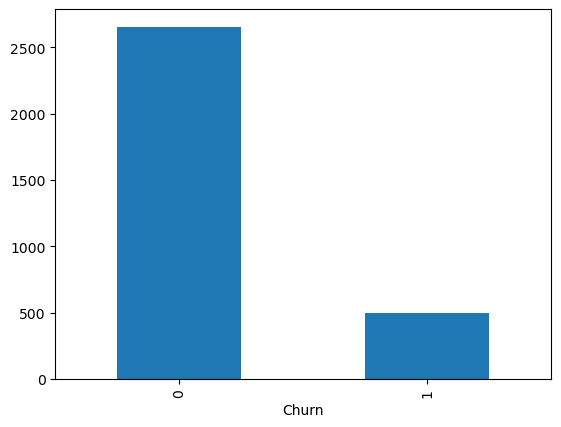

In [9]:
df['Churn'].value_counts().plot(kind='bar')



<Axes: xlabel='Churn', ylabel='count'>

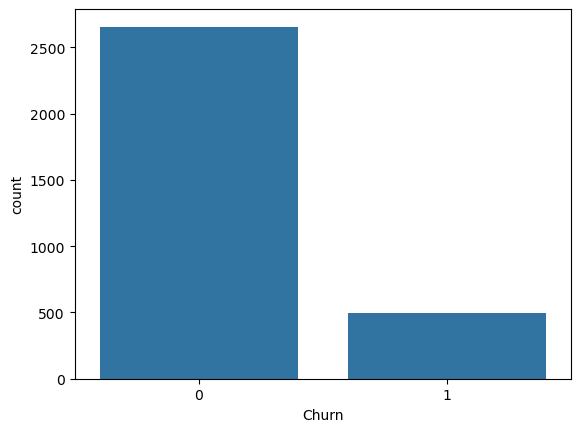

In [10]:
sns.countplot(x=df['Churn'])

In [11]:
df.isna().sum()

Call  Failure              0
Complains                  0
Subscription  Length       0
Charge  Amount             0
Seconds of Use             0
Frequency of use           0
Frequency of SMS           0
Distinct Called Numbers    0
Age Group                  0
Tariff Plan                0
Status                     0
Age                        0
Customer Value             0
Churn                      0
dtype: int64

## Without handling class imbalance

In [12]:
X = df.drop('Churn', axis=1)  
y = df['Churn']  

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# Train a Logistic Regression model
model = LogisticRegression(max_iter=2000)  # Increase max_iter if convergence issues occur
model.fit(X_train, y_train)

# Predict on the test set
y_pred = model.predict(X_test)
report = classification_report(y_test, y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.90      0.98      0.94       531
           1       0.77      0.41      0.54        99

    accuracy                           0.89       630
   macro avg       0.84      0.70      0.74       630
weighted avg       0.88      0.89      0.87       630



C:\Users\kshit\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=2000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


## Method 1: Undersampling

The correct approach is:

Original Dataset

Train-Test Split

Training Data

(Apply SMOTE) Or any sampling u wnt

Fit model on resampled data

Testing Data

(Keep original)

Evaluate on untouched data

Why only training data?

If we apply SMOTE before splitting:
1. Synthetic samples might be generated using observations that later enter the test set.
2. Information from the test set can leak into training.
3. Our evaluation results become overly optimistic.
This is called data leakage.

In [14]:
y_train.value_counts()

Churn
0    2124
1     396
Name: count, dtype: int64

In [19]:
from imblearn.under_sampling import RandomUnderSampler

rus=RandomUnderSampler(random_state=25)

X_train_rus,y_train_rus=rus.fit_resample(X_train,y_train) 
y_train_rus.value_counts()

Churn
0    396
1    396
Name: count, dtype: int64

## Why do we just fit resample just the train data not the test data

3. Why shouldn't we apply it to test data?
There are two important reasons.

Reason 1: Data leakage

Suppose you apply SMOTE before splitting your dataset.

SMOTE generates synthetic samples using existing observations and their nearest neighbors.

Some related information can then appear in both training and testing datasets.

As a result, your model might appear to perform better than it actually does.

Reason 2: Real-world evaluation

Think about your fraud detection model.

In the real world, you don't receive balanced data. You receive actual transactions, where fraud might represent only 1% of all transactions.

If you balance your test data, you are no longer testing the model on the original real-world distribution.

We want to know:
- How many actual fraud transactions can our model identify?
- How many normal transactions does it incorrectly classify as fraud?
- How reliable are its predictions in real-world conditions?
Therefore, testing data must retain its original class distribution.

In [20]:
model = LogisticRegression(max_iter=2000)
model.fit(X_train_rus, y_train_rus)

y_pred_rus = model.predict(X_test)
report = classification_report(y_test, y_pred_rus)
print(report)

              precision    recall  f1-score   support

           0       0.97      0.82      0.89       531
           1       0.47      0.87      0.61        99

    accuracy                           0.83       630
   macro avg       0.72      0.84      0.75       630
weighted avg       0.89      0.83      0.84       630



C:\Users\kshit\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=2000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


## Random OverSampling

In [22]:
from imblearn.over_sampling import RandomOverSampler

ros=RandomOverSampler(random_state=36)

X_train_ros, y_train_ros= ros.fit_resample(X_train,y_train)

y_train_ros.value_counts()

Churn
0    2124
1    2124
Name: count, dtype: int64

In [25]:
over_model=LogisticRegression(max_iter=2000)

over_model.fit(X_train_ros,y_train_ros)

over_y_pred=over_model.predict(X_test)

report_os=classification_report(y_test,over_y_pred)
print(report_os)

              precision    recall  f1-score   support

           0       0.97      0.83      0.89       531
           1       0.48      0.85      0.61        99

    accuracy                           0.83       630
   macro avg       0.72      0.84      0.75       630
weighted avg       0.89      0.83      0.85       630



C:\Users\kshit\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=2000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


## SMOTE

In [27]:
from imblearn.over_sampling import SMOTE

smote=SMOTE(random_state=99)

X_train_smote,y_train_smote=smote.fit_resample(X_train,y_train)

y_train_smote.value_counts()

Churn
0    2124
1    2124
Name: count, dtype: int64

In [28]:
model = LogisticRegression(max_iter=2000)
model.fit(X_train_smote, y_train_smote)

y_pred_smote = model.predict(X_test)
report = classification_report(y_test, y_pred_smote)
print(report)

              precision    recall  f1-score   support

           0       0.97      0.80      0.88       531
           1       0.44      0.85      0.58        99

    accuracy                           0.81       630
   macro avg       0.71      0.83      0.73       630
weighted avg       0.88      0.81      0.83       630



C:\Users\kshit\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=2000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [30]:
from imblearn.combine import SMOTETomek

smt=SMOTETomek(random_state=88)
X_tomek, y_tomek = smt.fit_resample(X_train, y_train)
y_tomek.value_counts()

Churn
0    2100
1    2100
Name: count, dtype: int64

In [31]:
model = LogisticRegression(max_iter=2000)
model.fit(X_tomek, y_tomek)

y_pred_tomek = model.predict(X_test)
report = classification_report(y_test, y_pred_tomek)
print(report)

              precision    recall  f1-score   support

           0       0.97      0.80      0.87       531
           1       0.44      0.85      0.58        99

    accuracy                           0.81       630
   macro avg       0.70      0.82      0.73       630
weighted avg       0.88      0.81      0.83       630



C:\Users\kshit\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=2000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
